# conversion funnel 

In [1]:
#importing data from big query
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
pd.set_option('display.max_columns', None)
pd.set_option('future.no_silent_downcasting', True)
# removed global float_format — apply .round(2) per-output instead, so conversion
# rates / corr() values don't get silently rounded to whole numbers

In [2]:
# from google_auth_oauthlib.flow import InstalledAppFlow

# SCOPES = [
#     "https://www.googleapis.com/auth/bigquery"
# ]

# flow = InstalledAppFlow.from_client_secrets_file(
#     "credentials.json",
#     SCOPES
# )

# credentials = flow.run_local_server(
#     host="localhost",
#     port=8080
# )

# print("Authentication successful!")

# # creating client 
# from google.cloud import bigquery

# client = bigquery.Client(
#     project="beaming-park-414712",
#     credentials=credentials
# )

# print("Connected successfully!")

# # quering all the tables 
# query = """
# SELECT
#     table_name
# FROM
#     `bigquery-public-data.google_analytics_sample.INFORMATION_SCHEMA.TABLES`
# ORDER BY
#     table_name
# """

# tables = client.query(query).to_dataframe()

# tables.head(20)

# data gathering 


In [3]:
# query = """
# SELECT
#     -- Session identifiers
#     session.fullVisitorId,
#     session.visitId,
#     session.visitNumber,
#     session.visitStartTime,
#     session.date,

#     -- Session-level totals
#     session.totals.hits AS totalHits,
#     session.totals.pageviews AS pageviews,
#     session.totals.timeOnSite AS timeOnSite,
#     session.totals.transactions AS transactions,
#     session.totals.transactionRevenue AS transactionRevenue,

#     -- Traffic source
#     session.trafficSource.campaign AS campaign,
#     session.trafficSource.source AS source,
#     session.channelGrouping,

#     -- Device
#     session.device.browser AS browser,
#     session.device.isMobile AS isMobile,
#     session.device.deviceCategory AS deviceCategory,

#     -- Geo
#     session.geoNetwork.continent AS continent,
#     session.geoNetwork.subContinent AS subcontinent,
#     session.geoNetwork.country AS country

# FROM
#     `bigquery-public-data.google_analytics_sample.ga_sessions_*` AS session
# """
# user = client.query(query).to_dataframe()
#------------------product table ----------------------------------------
# query = """
# SELECT
#   session.fullVisitorId,
#   hit.hitNumber,

#   product.productSKU,
#   product.v2ProductName,
#   product.v2ProductCategory,
#   product.productPrice,
#   product.productRevenue,
#   product.isClick

# FROM
#   `bigquery-public-data.google_analytics_sample.ga_sessions_*` AS session

# CROSS JOIN
#   UNNEST(session.hits) AS hit

# CROSS JOIN
#   UNNEST(hit.product) AS product
# WHERE
#   product.isClick = TRUE
#   OR product.productRevenue > 0
# """


# product_table1  = client.query(query).to_dataframe()

# data.to_csv("dataset.csv", index=False)
# product_table1.to_csv("product_table.csv",index=False)

# -------hits table -------------

# query = """
# SELECT
#     session.fullVisitorId,
#     session.visitId,
#     session.visitStartTime,
#     session.totals.timeOnSite AS timeOnSite,
#     hit.time AS hitTime,
#     session.date,
#     hit.hitNumber,
#     session.totals.hits AS totalHits,
#     hit.isEntrance,
#     hit.isExit,
#     hit.eCommerceAction.action_type AS actionType,
#     hit.page.pagePath AS pagePath

# FROM
#     `bigquery-public-data.google_analytics_sample.ga_sessions_*` AS session
# CROSS JOIN
#     UNNEST(session.hits) AS hit
# ORDER BY
#     session.fullVisitorId,
#     session.visitStartTime,
#     hit.hitNumber
# """
# hits_table = client.query(query).to_dataframe()


In [4]:
# hits_table.to_csv("hits.csv")

# data cleaning

# EDA

# users EDA

In [2]:
users = pd.read_csv("users.csv", dtype={'fullVisitorId': str})

In [3]:
users.describe()


,visitId,visitNumber,visitStartTime,date,totalHits,pageviews,timeOnSite,transactions,transactionRevenue
count,9.036530e+05,903653.000000,9.036530e+05,9.036530e+05,903653.000000,903553.000000,451894.000000,11552.000000,1.151500e+04
mean,1.485007e+09,2.264897,1.485007e+09,2.016589e+07,4.596538,3.849764,262.612141,1.048736,1.337448e+08
std,9.022124e+06,9.283735,9.022124e+06,4.697698e+03,9.641437,7.025274,485.509238,0.455401,4.482852e+08
min,1.470035e+09,1.000000,1.470035e+09,2.016080e+07,1.000000,1.000000,1.000000,1.000000,1.000000e+04
25%,1.477561e+09,1.000000,1.477561e+09,2.016103e+07,1.000000,1.000000,32.000000,1.000000,2.493000e+07
50%,1.483949e+09,1.000000,1.483949e+09,2.017011e+07,2.000000,1.000000,83.000000,1.000000,4.945000e+07
75%,1.492759e+09,1.000000,1.492759e+09,2.017042e+07,4.000000,4.000000,259.000000,1.000000,1.076550e+08
max,1.501657e+09,395.000000,1.501657e+09,2.017080e+07,500.000000,469.000000,19017.000000,25.000000,2.312950e+10


In [4]:
users.isna().sum()

fullVisitorId              0
visitId                    0
visitNumber                0
visitStartTime             0
date                       0
totalHits                  0
pageviews                100
timeOnSite            451759
transactions          892101
transactionRevenue    892138
campaign                   0
source                     0
channelGrouping            0
browser                    0
isMobile                   0
deviceCategory             0
continent                  0
subcontinent               0
country                    0
dtype: int64

In [5]:
def users_impute():
    users["transactionRevenue"] = users["transactionRevenue"].fillna(0)
    users["transactions"] = users["transactions"].fillna(0)
    users["timeOnSite"] = users["timeOnSite"].fillna(0)
    users["pageviews"] = users["pageviews"].fillna(np.mean(users["pageviews"]))
    users["timeOnSite"] = users["timeOnSite"].astype(int)
    users["pageviews"] = users["pageviews"].astype(int)
    users["campaign"] = users["campaign"].replace("(not set)", "Not_Set")
    users["source"] = users["source"].replace("(direct)", "Direct")
    # GA360 stores revenue in micros — convert to real currency
    users["transactionRevenue"] = users["transactionRevenue"] / 1_000_000

def users_formatting():
    users["visitStartTime"] = (
        pd.to_datetime(users["visitStartTime"], unit="s") - pd.Timedelta(hours=8)
    )
    users["date"] = pd.to_datetime(users["date"], format="%Y%m%d")

def users_feature_engineering():
    users["year"] = users["date"].dt.year
    users["month_name"] = users["date"].dt.month_name()
    users["day"] = users["date"].dt.day
    users["day_name"] = users["date"].dt.day_name()
    users["hour"] = users["visitStartTime"].dt.hour

users_impute()
users_formatting()
users_feature_engineering()

In [25]:
# 1 total customers
print(f" total unique users = {users["fullVisitorId"].nunique()}")

 total unique users = 714167


In [26]:
# which source has most pulled customers
source=users.groupby(users["source"])["fullVisitorId"].nunique().sort_values(ascending=False)
source.head(6)

source
Direct                  275411
youtube.com             201088
google                  197853
Partners                 13404
analytics.google.com     12115
google.com                4224
Name: fullVisitorId, dtype: int64

In [27]:
users["channelGrouping"].value_counts()

channelGrouping
Organic Search    381561
Social            226117
Direct            143026
Referral          104838
Paid Search        25326
Affiliates         16403
Display             6262
(Other)              120
Name: count, dtype: int64

In [93]:
device_summary = users.groupby("deviceCategory").agg(
    users=("fullVisitorId", "nunique"),
    sessions=("visitId", "nunique"),
    transactions=("transactions", "sum"),
    revenue=("transactionRevenue", "sum"),
    avg_time=("timeOnSite", "mean"),
    avg_pageviews=("pageviews", "mean")
)
device_summary["conversion_rate"] = (
    device_summary["transactions"]
    / device_summary["sessions"] * 100
)
device_summary["transactionRevenue_%"]=(device_summary["revenue"]/total_transaction)*100
device_summary

,users,sessions,transactions,revenue,avg_time,avg_pageviews,conversion_rate,transactionRevenue_%
deviceCategory,,,,,,,,
desktop,523690,653795,11071.0,1480864.09,136.715807,3.977298,1.693344,96.155558
mobile,166173,207512,866.0,49785.81,114.461234,3.419245,0.417325,3.232695
tablet,24304,30395,178.0,9421.34,129.302998,4.015009,0.585623,0.611747


In [91]:
channel_summary = users.groupby("channelGrouping").agg(
    users=("fullVisitorId", "nunique"),
    sessions=("visitId", "nunique"),
    revenue=("transactionRevenue", "sum"),
    transactions=("transactions", "sum")
)

channel_summary["conversion_rate"] = (
    channel_summary["transactions"]
    / channel_summary["sessions"]
    * 100
)

channel_summary["revenue_share"] = (
    channel_summary["revenue"]
    / channel_summary["revenue"].sum()
    * 100
)
channel_summary

,users,sessions,revenue,transactions,conversion_rate,revenue_share
channelGrouping,,,,,,
(Other),90,120,9.99,1.0,0.833333,0.000649
Affiliates,13400,16314,597.38,9.0,0.055167,0.038789
Direct,109830,141883,434840.55,2219.0,1.563965,28.235093
Display,4103,6255,78337.46,152.0,2.430056,5.086613
Organic Search,311607,377816,326380.51,3581.0,0.947816,21.192559
Paid Search,18702,25241,43558.90,479.0,1.897706,2.828369
Referral,65661,104255,651429.91,5543.0,5.316771,42.298687
Social,212374,224437,4916.54,131.0,0.058368,0.319241


In [94]:
hour_summary = users.groupby("hour").agg(
    users=("fullVisitorId", "nunique"),
    sessions=("visitId", "nunique"),
    transactions=("transactions", "sum"),
    revenue=("transactionRevenue", "sum")
)

hour_summary["conversion_rate"] = (
    hour_summary["transactions"]
    / hour_summary["sessions"] * 100
)
hour_summary

,users,sessions,transactions,revenue,conversion_rate
hour,,,,,
0,29729,30337,85.0,9655.55,0.280186
1,29101,29703,45.0,5866.27,0.151500
2,28922,29386,50.0,7409.81,0.170149
3,29879,30429,72.0,10048.42,0.236616
4,33226,33879,157.0,21489.86,0.463414
5,38214,39313,362.0,62449.34,0.920815
6,42095,43614,528.0,89476.41,1.210620
7,45377,47060,788.0,122407.92,1.674458
8,46194,47939,800.0,102336.10,1.668787


In [95]:
users[
    ["totalHits", "pageviews", "timeOnSite",
     "transactions", "transactionRevenue"]
].corr()

,totalHits,pageviews,timeOnSite,transactions,transactionRevenue
totalHits,1.000000,0.983202,0.662912,0.395171,0.154333
pageviews,0.983202,1.000000,0.688914,0.421613,0.155590
timeOnSite,0.662912,0.688914,1.000000,0.292724,0.109657
transactions,0.395171,0.421613,0.292724,1.000000,0.272278
transactionRevenue,0.154333,0.155590,0.109657,0.272278,1.000000


## univariate analysis 

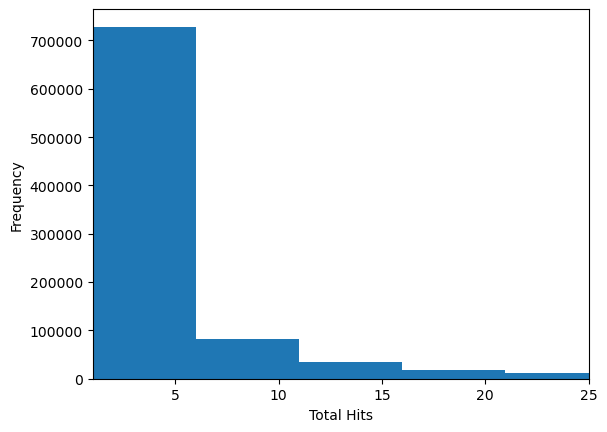

In [56]:
# distibution of hits 
plt.hist(users["totalHits"], bins=100)
plt.xlim(1, 25)
plt.xlabel("Total Hits")
plt.ylabel("Frequency")
plt.show()

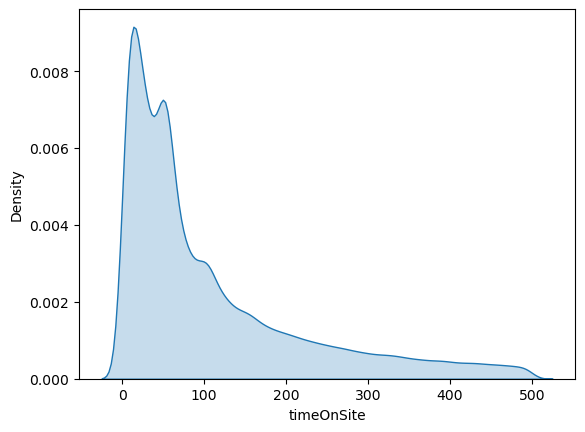

In [17]:
sns.kdeplot(data=users[users["timeOnSite"]<500],x="timeOnSite",fill=True)
plt.show() 

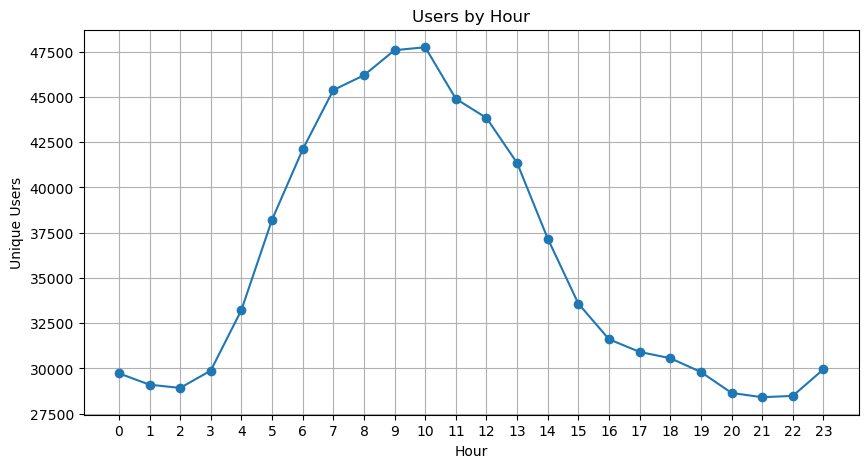

In [23]:
users_by_hour = users.groupby("hour")["fullVisitorId"].nunique()
plt.figure(figsize=(10, 5))

plt.plot(
    users_by_hour.index,
    users_by_hour.values,
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Unique Users")
plt.title("Users by Hour")

plt.xticks(range(24))
plt.grid()
plt.show()

## bivariate analysis


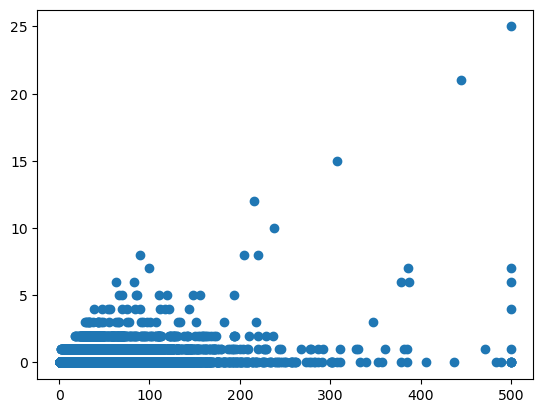

In [24]:
plt.scatter(x=users["totalHits"],y=users["transactions"])
plt.show()

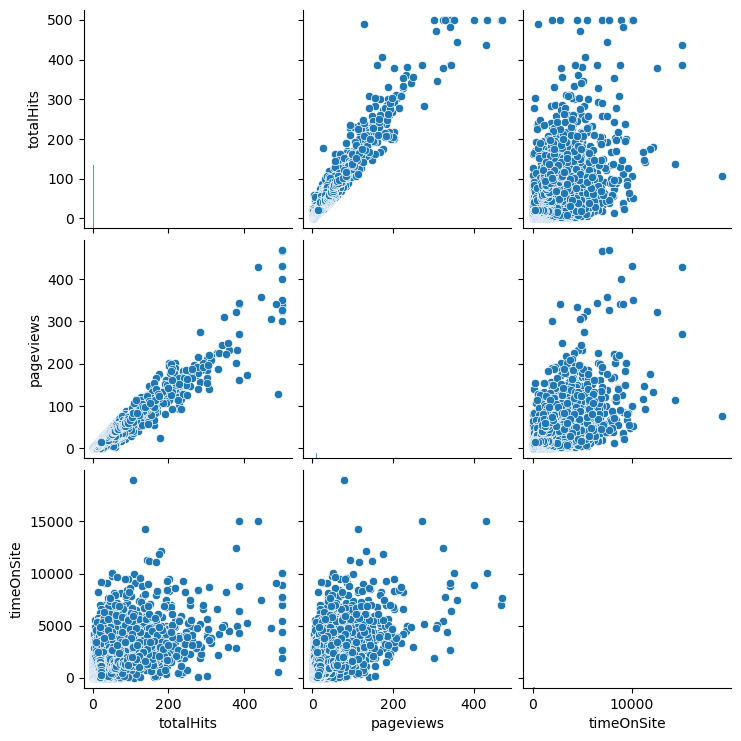

In [58]:
numerical_cols=['totalHits', 'pageviews', 'timeOnSite']
sns.pairplot(
    users[numerical_cols]
)

plt.show()

# Hits Table EDA 

In [6]:
hits = pd.read_csv("hits.csv", dtype={'fullVisitorId': str})
if "Unnamed: 0" in hits.columns:
    hits.drop(columns=["Unnamed: 0"], inplace=True)

In [100]:
hits.describe()

,visitId,visitStartTime,timeOnSite,hitTime,date,hitNumber,totalHits,actionType,duration_spent,hour
count,4.153675e+06,4153675,4.153675e+06,4.153675e+06,4153675,4.153675e+06,4.153675e+06,4.153675e+06,3.250022e+06,4.153675e+06
mean,1.484483e+09,2017-01-15 04:24:31.893647872,6.424466e+02,3.092680e+05,2017-01-14 16:32:30.232890624,1.295718e+01,2.481985e+01,5.273224e-01,3.651841e+01,1.188542e+01
min,1.470035e+09,2016-07-31 23:00:12,0.000000e+00,0.000000e+00,2016-08-01 00:00:00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.476384e+09,2016-10-13 10:39:02,6.200000e+01,7.305000e+03,2016-10-13 00:00:00,2.000000e+00,4.000000e+00,0.000000e+00,3.618000e+00,7.000000e+00
50%,1.483162e+09,2016-12-30 21:24:54,2.730000e+02,8.625400e+04,2016-12-30 00:00:00,5.000000e+00,1.200000e+01,0.000000e+00,1.105900e+01,1.200000e+01
75%,1.492530e+09,2017-04-18 07:44:59,8.120000e+02,3.266870e+05,2017-04-18 00:00:00,1.400000e+01,3.000000e+01,1.000000e+00,2.785700e+01,1.700000e+01
max,1.501657e+09,2017-08-01 22:59:53,1.901700e+04,1.901676e+07,2017-08-01 00:00:00,5.000000e+02,5.000000e+02,6.000000e+00,2.363225e+03,2.300000e+01
std,9.282109e+06,NaN,1.010556e+03,6.171769e+05,NaN,2.417649e+01,3.988711e+01,1.117678e+00,1.173205e+02,6.007524e+00


In [16]:
print(hits.columns)

Index(['fullVisitorId', 'visitId', 'visitStartTime', 'timeOnSite', 'hitTime',
       'date', 'hitNumber', 'totalHits', 'isEntrance', 'isExit', 'actionType',
       'pagePath', 'action_performed', 'duration_spent', 'hit_start_time',
       'hour'],
      dtype='object')


In [7]:
def hits_cleaning():
    hits["date"] = pd.to_datetime(hits["date"], format="%Y%m%d")
    hits["visitStartTime"] = (
        pd.to_datetime(hits["visitStartTime"], unit="s") - pd.Timedelta(hours=8)
    )
    hits["isEntrance"] = hits["isEntrance"].fillna(False).astype(bool)
    hits["isExit"] = hits["isExit"].fillna(False).astype(bool)
    hits["timeOnSite"] = hits["timeOnSite"].fillna(0).astype(int)

def hits_mapping():
    hits["action_performed"] = hits["actionType"].map({
        0: "page view",
        1: "product click",
        2: "product details",
        3: "add to cart",
        4: "remove_from_cart",
        5: "checkout",
        6: "purchase",
        7: "refund",
        8: "checkout_options",   # was wrongly "add_to_wishlist"
        9: "unknown"
    })

def hits_feature_engineering_hits():
    # sort first — shift() needs hits in true hitNumber order within each session
    hits.sort_values(["fullVisitorId", "visitId", "hitNumber"], inplace=True)

    hits["next_hitTime"] = hits.groupby(["fullVisitorId", "visitId","date"])["hitTime"].shift(-1)
    hits["duration_spent"] = (hits["next_hitTime"] - hits["hitTime"]) / 1000

    hits["hit_start_time"] = hits["visitStartTime"] + pd.to_timedelta(hits["hitTime"], unit="ms")
    hits["hour"] = hits["hit_start_time"].dt.hour
    hits["hit_start_time"] = hits["hit_start_time"].dt.strftime("%H:%M:%S")

def hits_drop_columns():
    hits.drop("next_hitTime", inplace=True, axis=1)

hits_cleaning()
hits_mapping()
hits_feature_engineering_hits()
hits_drop_columns()

In [11]:
hits_per_session = (
    hits.groupby(["fullVisitorId", "visitId"])
        .size()
        .reset_index(name="total_hits")
)
total_hits = hits_per_session["total_hits"].sum()
print(f"total hits : {total_hits}")
print(f"Average hits per session: {round(total_hits/len(hits_per_session))}")

total hits : 4153675
Average hits per session: 5


In [12]:
(hits["action_performed"].value_counts(normalize=True) * 100).round(2).astype(str) + "%"

action_performed
page view            74.5%
product click       10.73%
product details      8.73%
add to cart          2.92%
checkout             2.12%
purchase             0.59%
remove_from_cart     0.41%
Name: proportion, dtype: object

In [13]:
hits["isEntrance"].value_counts()

isEntrance
False    3250122
True      903553
Name: count, dtype: int64

In [82]:
entrance_pages = (
    hits[hits["isEntrance"] == True]
    .groupby("pagePath")["fullVisitorId"]
    .nunique()
    .sort_values(ascending=False)
)
entrance_page=round((entrance_pages/entrance_pages.sum())*100,2)
print(entrance_page.head())

pagePath
/home                                              67.07
/google+redesign/shop+by+brand/youtube              9.84
/google+redesign/apparel/men++s/men++s+t+shirts     2.48
/google+redesign/apparel/mens/mens+t+shirts         1.52
/signin.html                                        1.38
Name: fullVisitorId, dtype: float64


In [77]:
# Your existing code
exit_pages = (
    hits[hits["isExit"] == True]
    .groupby("pagePath")["fullVisitorId"]
    .nunique()
    .sort_values(ascending=False)
)

# Convert to percentage of total exits
exit_pages_pct = round((exit_pages / exit_pages.sum()) * 100)

print(exit_pages_pct.head())

pagePath
/home                                     46.0
/google+redesign/shop+by+brand/youtube     8.0
/signin.html                               3.0
/basket.html                               2.0
/asearch.html                              2.0
Name: fullVisitorId, dtype: float64


In [38]:
# Explicit funnel order — not sorted by volume, so it stays correct under any segment/filter
funnel_stages = ["page view", "product click", "product details", "add to cart", "checkout", "purchase"]

user_hits = (
    hits[hits["action_performed"].isin(funnel_stages)]
    .groupby("action_performed")
    .agg(total_hits=("visitId", "size"))
    .reindex(funnel_stages)
    .reset_index()
    .rename(columns={"action_performed": "action_type"})
)

user_hits["drop"] = (user_hits["total_hits"] - user_hits["total_hits"].shift(-1)).fillna(0).astype(int)
user_hits["drop%"] = (user_hits["total_hits"] - user_hits["total_hits"].shift(-1)) * 100 / user_hits["total_hits"]

user_hits

,action_type,total_hits,drop,drop%
0,page view,3094384,2648624,85.594548
1,product click,445760,83153,18.654209
2,product details,362607,241180,66.512781
3,add to cart,121427,33408,27.512827
4,checkout,88019,63487,72.128745
5,purchase,24532,0,NaN


In [39]:
# remove_from_cart handled separately as cart leakage, not a funnel stage
atc_hits = (hits["action_performed"] == "add to cart").sum()
removed_hits = (hits["action_performed"] == "remove_from_cart").sum()
print(f"Cart removal rate: {removed_hits / atc_hits * 100:.1f}% of add-to-cart events were later removed")

Cart removal rate: 14.0% of add-to-cart events were later removed


In [40]:
exit_pages = (
    hits[hits["isExit"] == True]
    .groupby("pagePath")["fullVisitorId"]
    .nunique()
    .sort_values(ascending=False)
)
print(exit_pages.head())

pagePath
/home                                     374500
/google+redesign/shop+by+brand/youtube     64899
/signin.html                               23048
/basket.html                               19052
/asearch.html                              18183
Name: fullVisitorId, dtype: int64


## hits visulalization

<Axes: xlabel='action_performed'>

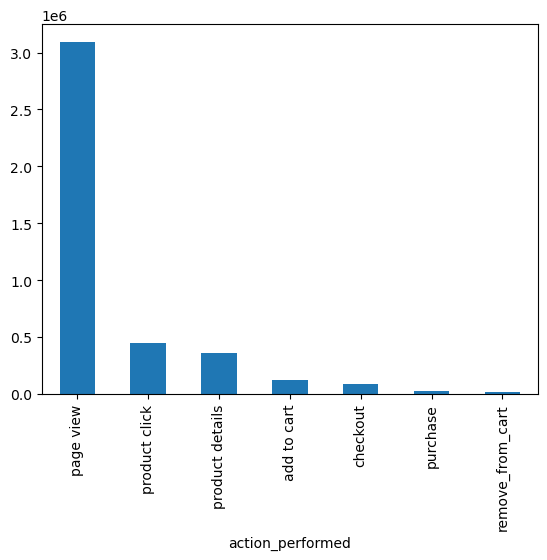

In [41]:
hits["action_performed"].value_counts().plot(kind="bar")

<Axes: ylabel='count'>

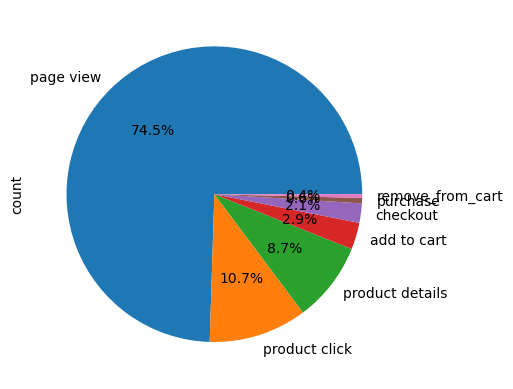

In [42]:
hits["action_performed"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

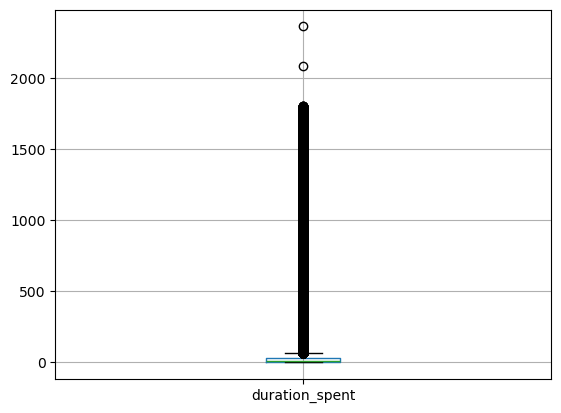

In [25]:
hits.boxplot(column="duration_spent")
plt.show()

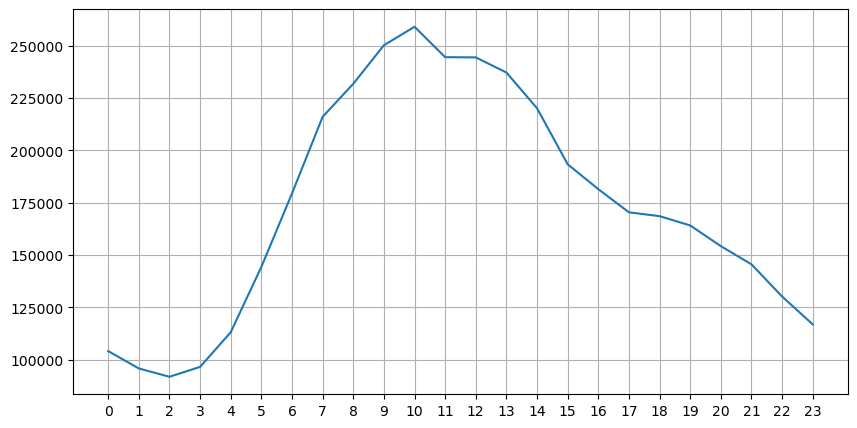

In [21]:
hits_by_hour = hits.groupby("hour")["visitId"].size()
plt.figure(figsize=(10, 5))

plt.plot(
    hits_by_hour.index,
    hits_by_hour.values)
plt.xticks(range(24))
plt.grid()
plt.show()

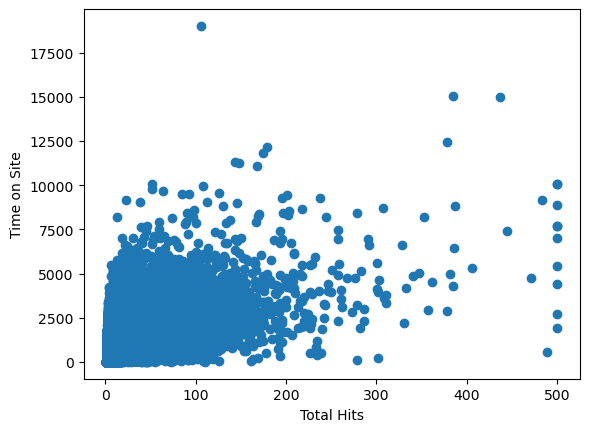

In [44]:
session_data = hits.groupby("visitId").agg({
    "timeOnSite": "first",
    "totalHits": "first"
})

plt.scatter(
    session_data["totalHits"],
    session_data["timeOnSite"]
)
plt.xlabel("Total Hits")
plt.ylabel("Time on Site")
plt.show()

# proudcts 

In [8]:
products = pd.read_csv("product.csv", dtype={'fullVisitorId': str})

In [34]:
products.head()

,fullVisitorId,hitNumber,productSKU,v2ProductName,v2ProductCategory,productPrice,productRevenue,isClick
0,7474443254829193449,3,GGOEGAAX0105,Google Men's 100% Cotton Short Sleeve Hero Tee...,Home/Apparel/Men's/Men's-T-Shirts/,16990000,NaN,True
1,8985084471729758797,3,GGOEGAAX0331,Google Men's Long Sleeve Raglan Ocean Blue,Home/Apparel/Men's/Men's-T-Shirts/,24990000,NaN,True
2,8642248967495128637,3,GGOEGBRA037499,Waterproof Backpack,Home/Bags/,99990000,NaN,True
3,3374348769230694768,2,GGOEGAAX0661,You Tube Toddler Short Sleeve Tee Red,Home/Shop by Brand/YouTube/,16990000,NaN,True
4,1082735241224806813,2,GGOEGAAX0686,YouTube Youth Short Sleeve Tee Red,Home/Apparel/Kid's/Kids-Youth/,18990000,NaN,True


In [42]:
products.isna().sum()

fullVisitorId        0
hitNumber            0
productSKU           0
v2ProductName        0
v2ProductCategory    0
productPrice         0
productRevenue       0
isClick              0
dtype: int64

In [99]:
print(products.duplicated().sum())
products=products.drop_duplicates()

3203


In [9]:
def product_cleaning():
    products["productRevenue"] = products["productRevenue"].fillna(0) / 1e6
    products["isClick"] = products["isClick"].fillna(False)
product_cleaning()

In [42]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482578 entries, 0 to 482577
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fullVisitorId      482578 non-null  object 
 1   hitNumber          482578 non-null  int64  
 2   productSKU         482578 non-null  object 
 3   v2ProductName      482578 non-null  object 
 4   v2ProductCategory  482578 non-null  object 
 5   productPrice       482578 non-null  int64  
 6   productRevenue     482578 non-null  float64
 7   isClick            482578 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 29.5+ MB


In [100]:
products["isClick"].value_counts()

isClick
True     442677
False     36698
Name: count, dtype: int64

In [101]:
# total revunue
print(products["productRevenue"].sum().astype(int))

1738230


In [45]:
# which product is clicked 
click=products.groupby("v2ProductName").size()
click.sort_values(ascending=False).head(5)

v2ProductName
Google Men's 100% Cotton Short Sleeve Hero Tee White    15450
Google Alpine Style Backpack                            11219
Waterproof Backpack                                     11106
Google Men's  Zip Hoodie                                 9958
Google Rucksack                                          8488
dtype: int64

In [46]:
buy = products.groupby("v2ProductName").agg(
    total_revenue=("productRevenue", "sum"),
    appearance=("v2ProductName", "size")
)

buy["appearance_percentage"] = (
    buy["appearance"] / buy["appearance"].sum() * 100
)

buy["total_revenue_percentage"] = (
    buy["total_revenue"] / buy["total_revenue"].sum() * 100
)

buy = buy.sort_values("appearance", ascending=False).head(5)

buy

,total_revenue,appearance,appearance_percentage,total_revenue_percentage
v2ProductName,,,,
Google Men's 100% Cotton Short Sleeve Hero Tee White,27856.018891,15450,3.201555,1.599039
Google Alpine Style Backpack,14451.939090,11219,2.324806,0.829595
Waterproof Backpack,19379.836853,11106,2.301390,1.112475
Google Men's Zip Hoodie,47636.271605,9958,2.063501,2.734500
Google Rucksack,17643.699369,8488,1.758887,1.012814


# business questions 

In [ ]:
Yes. For your **GA360 E-Commerce Funnel Analysis** project, I’d make the notebook headings more professional and consistent. Your current headings are understandable, but names like `proudcts` and `users EDA` look informal.

### Recommended notebook structure

```text
# 1. Project Overview
```

Briefly explain the business problem, dataset, objectives, and tools.

```text
# 2. Data Gathering & Dataset Understanding
```

Instead of just `data gathering`.

```text
# 3. Data Cleaning & Preprocessing
```

Include missing values, duplicates, data types, nested columns, invalid values, etc.

```text
# 4. Exploratory Data Analysis (EDA)
```

Then divide EDA into:

```text
## 4.1 User-Level Analysis
```

```text
## 4.2 Session & Traffic Analysis
```

```text
## 4.3 Hit-Level Analysis
```

```text
## 4.4 Product & Revenue Analysis
```

This is better than having separate headings like `users EDA`, `Hits Table EDA`, and `products`.

---

### Then your most important section

```text
# 5. E-Commerce Funnel Analysis
```

You can break it down into:

```text
## 5.1 Funnel Overview
```

```text
## 5.2 User Acquisition
```

```text
## 5.3 User Engagement
```

```text
## 5.4 Product Interaction
```

```text
## 5.5 Purchase Conversion
```

```text
## 5.6 Revenue & Customer Value
```

---

### Business questions

Instead of:

> `business questions`

use:

```text
# 6. Business Questions & Insights
```

Then organize the questions:

```text
## 6.1 Traffic & Acquisition
```

```text
## 6.2 User Behavior
```

```text
## 6.3 Engagement & Navigation
```

```text
## 6.4 Product Performance
```

```text
## 6.5 Conversion & Funnel Performance
```

```text
## 6.6 Revenue Analysis
```

```text
## 6.7 Customer Behavior
```

---

### Finish with

```text
# 7. Key Findings
```

```text
# 8. Business Recommendations
```

```text
# 9. Conclusion
```

## My recommended final hierarchy

```text
1. Project Overview
2. Data Gathering & Dataset Understanding
3. Data Cleaning & Preprocessing

4. Exploratory Data Analysis
   ├── User-Level Analysis
   ├── Session & Traffic Analysis
   ├── Hit-Level Analysis
   └── Product & Revenue Analysis

5. E-Commerce Funnel Analysis
   ├── Funnel Overview
   ├── User Acquisition
   ├── User Engagement
   ├── Product Interaction
   ├── Purchase Conversion
   └── Revenue & Customer Value

6. Business Questions & Insights
   ├── Traffic & Acquisition
   ├── User Behavior
   ├── Engagement & Navigation
   ├── Product Performance
   ├── Conversion & Funnel Performance
   ├── Revenue Analysis
   └── Customer Behavior

7. Key Findings
8. Business Recommendations
9. Conclusion
```

**One important improvement:** I would keep **EDA** and **Business Questions** separate. EDA tells the story of *what the data looks like*, while Business Questions tells the story of *what the business should learn from it*. That separation will make your project look much more professional in a portfolio/interview.


In [26]:
#1)How much traffic does the site receive?

total_sessions = len(users)
total_unique_visitors = users["fullVisitorId"].nunique()
print(f"Total sessions: {total_sessions}")
print(f"Total unique visitors: {total_unique_visitors}")

Total sessions: 903653
Total unique visitors: 714167


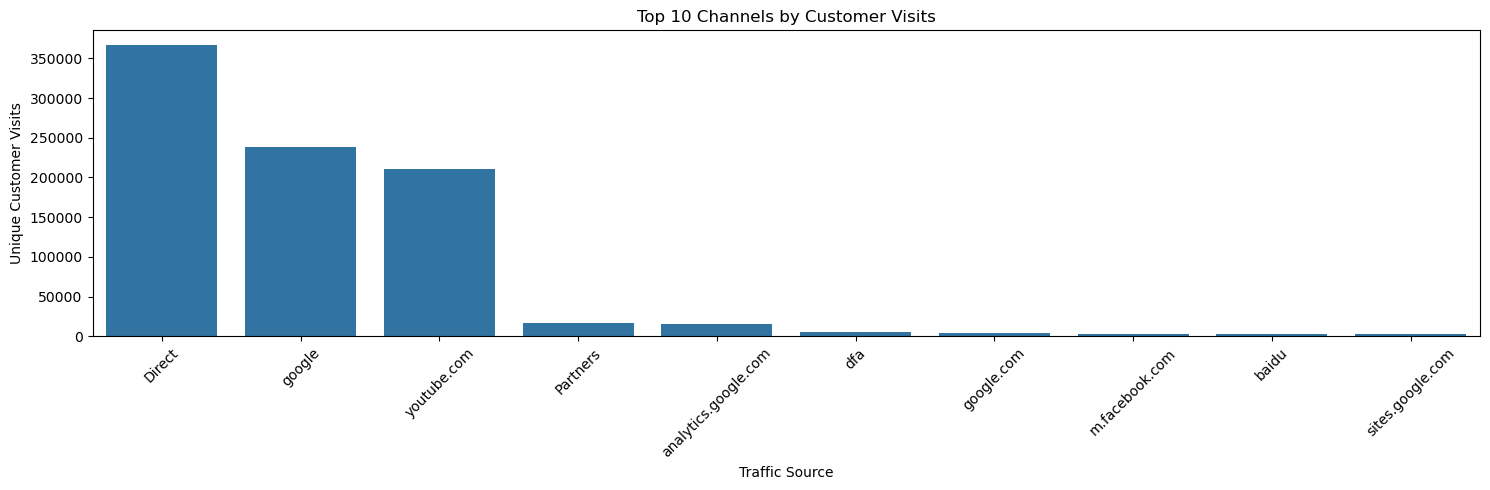

In [73]:
#2)Top 10 source by customer visits

source = (
    users.groupby("source")["visitId"]
    .nunique()
    .sort_values(ascending=False)
)

source_channels = source.head(10)

plt.figure(figsize=(15, 5))
sns.barplot(
    x=source_channels.index,
    y=source_channels.values
)

plt.xticks(rotation=45)
plt.xlabel("Traffic Source")
plt.ylabel("Unique Customer Visits")
plt.title("Top 10 Channels by Customer Visits")
plt.tight_layout()
plt.show()

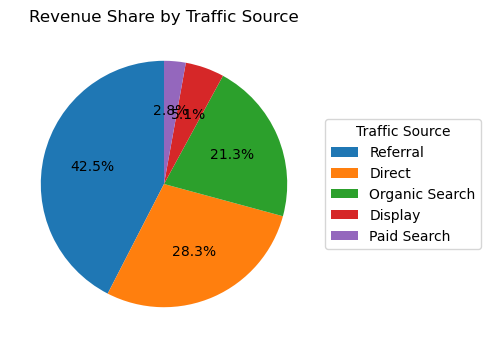

In [70]:
#3) which channel generates more revenue 
source_summary = users.groupby("channelGrouping").agg(
    transactionRevenue=("transactionRevenue", "sum")
).sort_values(by="transactionRevenue", ascending=False)

total_transaction = users["transactionRevenue"].sum()
source_summary["transactionRevenue_%"] = source_summary["transactionRevenue"] * 100 / total_transaction
source_chart = source_summary.head(5)

plt.figure(figsize=(4, 4))
plt.pie(source_chart["transactionRevenue_%"],  # ✅ Fixed: was "revenue_%"
    labels=None,
    autopct="%1.1f%%",
    startangle=90)
plt.legend(
    source_chart.index,
    title="Traffic Source",
    loc="center left",
    bbox_to_anchor=(1, 0.5))
plt.title("Revenue Share by channels")
plt.show()

In [83]:
# 4. Device & Engagement
t_hits=sum(users["totalHits"])
avg_hits_by_device=users.groupby("deviceCategory").agg(total_hits=("totalHits","sum"),total_users=("visitId","count"))
avg_hits_by_device["avg_hits"]=avg_hits_by_device["total_hits"]/avg_hits_by_device["total_users"]
avg_hits_by_device

,total_hits,total_users,avg_hits
deviceCategory,,,
desktop,3171344,664479,4.772678
mobile,838327,208725,4.016419
tablet,144004,30449,4.729351


In [90]:
# 5)How does device type affect transactions?
revenue_by_device=users.groupby("deviceCategory").agg(total_users=("fullVisitorId","nunique"),total_transactions=("transactions","sum"))
revenue_by_device["conversion_rate"]=round((revenue_by_device["total_transactions"]/revenue_by_device["total_users"])*100,2)
revenue_by_device

,total_users,total_transactions,conversion_rate
deviceCategory,,,
desktop,523690,11071.0,2.11
mobile,166173,866.0,0.52
tablet,24304,178.0,0.73


              transactions  totalHits
transactions      1.000000   0.395171
totalHits         0.395171   1.000000


C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


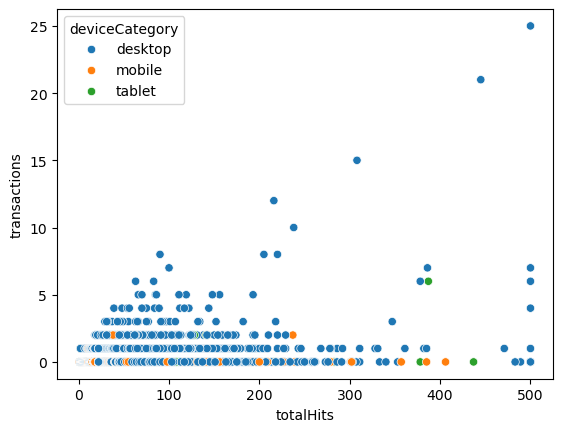

In [31]:
print(users[["transactions","totalHits"]].corr())
sns.scatterplot(y=users["transactions"], x=users["totalHits"], hue=users["deviceCategory"])
plt.show()

### funnel & conversion

In [5]:
# 1 funnel stages 
funnel_stages = ["page view", "product click", "product details", "add to cart", "checkout", "purchase"]

# one row per session, with the set of distinct actions performed in that session
session_actions = (
    hits.groupby(["fullVisitorId", "visitId"])["action_performed"]
        .apply(set)
        .reset_index()
        .rename(columns={"action_performed": "actions_set"})
)
# above code o/p  - 123	| 456 | {"page view", "product click", "purchase"}

# boolean flag per stage: did this session include this action ANYWHERE (no order requirement)?
for stage in funnel_stages:
    session_actions[stage] = session_actions["actions_set"].apply(lambda s: stage in s)
 
#fullVisitorId	visitId	actions_set	page view	product click	...	purchase
 #o/p    123	456	{...}	True	True	...	True

# count distinct sessions that reached each stage, independent of order
funnel_counts = {stage: session_actions[stage].sum() for stage in funnel_stages}
# {"page view": 45000, "product click": 20000, "add to cart": 9500, "purchase": 11551}
funnel_df = pd.DataFrame(list(funnel_counts.items()), columns=["stage", "sessions"])
funnel_df["conversion_from_prev"] = (funnel_df["sessions"] / funnel_df["sessions"].shift(1) * 100).round(2)
funnel_df["conversion_from_start"] = (funnel_df["sessions"] / funnel_df["sessions"].iloc[0] * 100).round(2)
funnel_df

,stage,sessions,conversion_from_prev,conversion_from_start
0,page view,902064,NaN,100.00
1,product click,124356,13.79,13.79
2,product details,124053,99.76,13.75
3,add to cart,50098,40.38,5.55
4,checkout,22386,44.68,2.48
5,purchase,11551,51.60,1.28


In [68]:
# 2 cart leakage
# cart abandonment: add-to-cart sessions that never purchased
atc = funnel_df.loc[funnel_df["stage"]=="add to cart", "sessions"].values[0]
purchased = funnel_df.loc[funnel_df["stage"]=="purchase", "sessions"].values[0]
cart_abandonment = 100 - round((purchased/atc)*100, 2)
print(f"Cart abandonment rate: {cart_abandonment}%")

# separately: true remove_from_cart leakage, as originally scoped
removed = (hits["action_performed"]=="remove_from_cart").sum()
added = (hits["action_performed"]=="add to cart").sum()
print(f"Explicit cart removal rate: {removed/added*100:.1f}%")

Cart abandonment rate: 76.94%
Explicit cart removal rate: 14.0%


In [176]:
#3 new vs returing customer 
new_return_df = users.groupby("fullVisitorId").agg(
    visitNumber=("visitNumber", "max"),
    transaction=("transactions", "sum")
)

# New users
new_users = new_return_df[new_return_df["visitNumber"] == 1]

new_count = len(new_users)
new_transaction = (new_users["transaction"] > 0).sum()

# Returning users
return_users = new_return_df[new_return_df["visitNumber"] > 1]

return_count = len(return_users)
return_transaction = (return_users["transaction"] > 0).sum()

print("New users:", new_count)
print("New users with transaction:", new_transaction)

print("Returning users:", return_count)
print("Returning users with transaction:", return_transaction)

new_conversion = (new_transaction / new_count) * 100
return_conversion = return_transaction / return_count * 100

print(f"New user conversion rate: {new_conversion:.2f}%")
print(f"Returning user conversion rate: {return_conversion:.2f}%")

New users: 614691
New users with transaction: 2970
Returning users: 99476
Returning users with transaction: 7052
New user conversion rate: 0.48%
Returning user conversion rate: 7.09%


##  Page-Level Behavior

In [26]:
# top 10 visited pages
page_level=hits.groupby("pagePath").agg(total_users=("visitId","nunique")).sort_values(by="total_users",ascending=False).head(10)
page_level

,total_users
pagePath,
/home,641024
/google+redesign/shop+by+brand/youtube,113748
/signin.html,71937
/basket.html,71044
/store.html,54915
/google+redesign/apparel/men++s/men++s+t+shirts,51265
/google+redesign/electronics,45053
/google+redesign/apparel,41583
/google+redesign/bags,41521


In [60]:
#Product-level "high interaction but low purchasing" ratio  
products["product_revenue"] = np.where(products["productRevenue"] > 0,1,0)
interaction=products.groupby("v2ProductName").agg(total_interactions=("fullVisitorId","count")
    ,purchased=("product_revenue","sum")).sort_values(by="total_interactions",ascending=False)
interaction["purchase_%"]= (interaction["purchased"]/interaction["total_interactions"])*100
interaction.sort_values(by=["total_interactions","purchase_%"],ascending=False).head(20)

,total_interactions,purchased,purchase_%
v2ProductName,,,
Google Men's 100% Cotton Short Sleeve Hero Tee White,15450,760,4.919094
Google Alpine Style Backpack,11219,96,0.855691
Waterproof Backpack,11106,131,1.179543
Google Men's Zip Hoodie,9958,468,4.699739
Google Rucksack,8488,124,1.460886
Google Sunglasses,8344,1364,16.347076
Google Laptop and Cell Phone Stickers,8100,788,9.728395
YouTube Custom Decals,7167,344,4.799777
Keyboard DOT Sticker,7024,187,2.662301


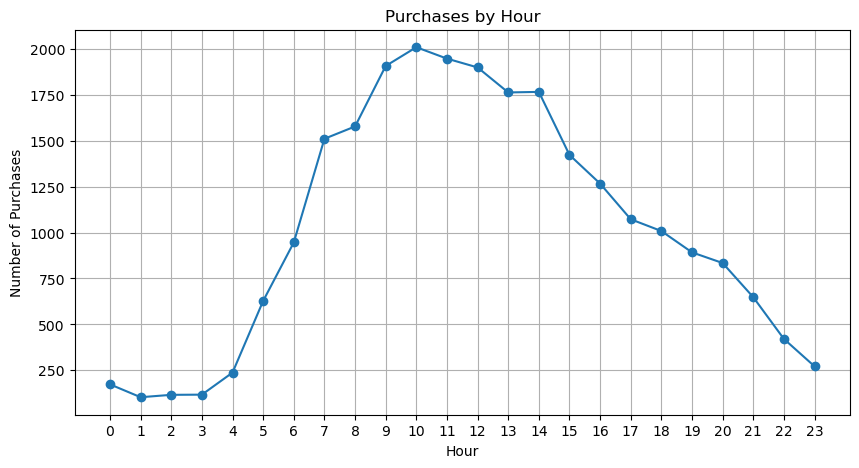

In [67]:
# Filter only purchase events
purchase = hits[hits["action_performed"] == "purchase"]

# Count purchases for each hour
purchase_by_hour = (
    purchase.groupby("hour")
    .agg(total_purchase=("action_performed", "count"))
    .reset_index()
)

# Sort by hour
purchase_by_hour = purchase_by_hour.sort_values("hour")

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    purchase_by_hour["hour"],
    purchase_by_hour["total_purchase"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Number of Purchases")
plt.title("Purchases by Hour")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [ ]:
#(new-vs-returning gap, cart abandonment, device conversion gap are your three strongest findings)

In [12]:
users.to_csv("users_df",index=False)

,fullVisitorId,hitNumber,productSKU,v2ProductName,v2ProductCategory,productPrice,productRevenue,isClick
0,7474443254829193449,3,GGOEGAAX0105,Google Men's 100% Cotton Short Sleeve Hero Tee...,Home/Apparel/Men's/Men's-T-Shirts/,16990000,0.0,True
1,8985084471729758797,3,GGOEGAAX0331,Google Men's Long Sleeve Raglan Ocean Blue,Home/Apparel/Men's/Men's-T-Shirts/,24990000,0.0,True
2,8642248967495128637,3,GGOEGBRA037499,Waterproof Backpack,Home/Bags/,99990000,0.0,True
3,3374348769230694768,2,GGOEGAAX0661,You Tube Toddler Short Sleeve Tee Red,Home/Shop by Brand/YouTube/,16990000,0.0,True
4,1082735241224806813,2,GGOEGAAX0686,YouTube Youth Short Sleeve Tee Red,Home/Apparel/Kid's/Kids-Youth/,18990000,0.0,True
...,...,...,...,...,...,...,...,...
482573,3089532831110947358,12,GGOEGESC014099,Rocket Flashlight,Home/Electronics/Flashlights/,4990000,0.0,True
482574,3089532831110947358,17,GGOEGOAB021699,Google Ballpoint Pen Black,${escCatTitle},1990000,0.0,True
482575,3089532831110947358,19,GGOEGOAB021699,Google Ballpoint Pen Black,${escCatTitle},1990000,0.0,True
482576,3089532831110947358,21,GGOEGOAQ018099,Pen Pencil & Highlighter Set,${escCatTitle},3990000,0.0,True


## root cause analysis

In [6]:
# session-level funnel flags, joined with segment attributes
session_actions = hits.groupby(["fullVisitorId","visitId"])["action_performed"].apply(set).reset_index()
for stage in funnel_stages:
    session_actions[stage] = session_actions["action_performed"].apply(lambda s: stage in s)

funnel_seg = session_actions.merge(
    users[["fullVisitorId","visitId","deviceCategory","channelGrouping","source","browser","country"]],
    on=["fullVisitorId","visitId"], how="left"
)

def drop_by_segment(from_stage, to_stage, dim):
    g = funnel_seg.groupby(dim).agg(
        from_count=(from_stage,"sum"),
        to_count=(to_stage,"sum")
    )
    # g = g[g["from_count"] >= min_sessions]   # drop tiny segments — noisy %s
    g["conversion_%"] = g["to_count"]/g["from_count"]*100
    g["drop_%"] = 100 - g["conversion_%"]
    return g.sort_values("drop_%", ascending=False)
drop_by_segment("product details", "add to cart", "deviceCategory")
drop_by_segment("add to cart", "purchase", "deviceCategory")     # checkout+purchase combined for simplicity, or swap in "checkout"
drop_by_segment("add to cart", "purchase", "browser")
drop_by_segment("add to cart", "purchase", "channelGrouping")

,from_count,to_count,conversion_%,drop_%
channelGrouping,,,,
Affiliates,803,9,1.120797,98.879203
Social,1772,104,5.869074,94.130926
Organic Search,22446,3458,15.405863,84.594137
Direct,9268,2064,22.270177,77.729823
Paid Search,1914,471,24.608150,75.391850
(Other),4,1,25.000000,75.000000
Display,541,143,26.432532,73.567468
Referral,13549,5338,39.397742,60.602258


In [8]:
mobile_conv = funnel_seg[funnel_seg["deviceCategory"]=="mobile"]
desktop_rate = drop_by_segment("add to cart","purchase","deviceCategory").loc["desktop","conversion_%"]
current_mobile_purchases = mobile_conv["purchase"].sum()
potential_purchases = mobile_conv["add to cart"].sum() * (desktop_rate/100)
lost_purchases = potential_purchases - current_mobile_purchases
print(f"If mobile converted at desktop's rate, ~{lost_purchases:.0f} more purchases would have occurred")

If mobile converted at desktop's rate, ~1327 more purchases would have occurred


In [21]:
hits=hits[['fullVisitorId', 'visitId','date','totalHits', 'isEntrance', 'isExit', 'actionType',
       'pagePath', 'action_performed','hour']]

In [21]:
users=users[['fullVisitorId', 'visitId', 'visitNumber','date',
       'totalHits','timeOnSite', 'transactions',
       'transactionRevenue','channelGrouping','deviceCategory', 'continent', 'year', 'month_name', 'day', 'day_name', 'hour']]

In [24]:
products[['fullVisitorId','v2ProductName', 'productRevenue']]

,fullVisitorId,v2ProductName,productRevenue
0,7474443254829193449,Google Men's 100% Cotton Short Sleeve Hero Tee...,0.0
1,8985084471729758797,Google Men's Long Sleeve Raglan Ocean Blue,0.0
2,8642248967495128637,Waterproof Backpack,0.0
3,3374348769230694768,You Tube Toddler Short Sleeve Tee Red,0.0
4,1082735241224806813,YouTube Youth Short Sleeve Tee Red,0.0
...,...,...,...
482573,3089532831110947358,Rocket Flashlight,0.0
482574,3089532831110947358,Google Ballpoint Pen Black,0.0
482575,3089532831110947358,Google Ballpoint Pen Black,0.0
482576,3089532831110947358,Pen Pencil & Highlighter Set,0.0


In [41]:
hits.to_csv("hits_df.csv")
users.to_csv("users_df.csv")
products.to_csv("products_df.csv")

In [23]:
hits["fullVisitorId"].describe()

count                 4153675
unique                 714167
top       1957458976293878100
freq                     4995
Name: fullVisitorId, dtype: object

In [7]:
print(users["transactions"].sum())


12115.0


In [8]:
print(users["transactionRevenue"].sum())

1540071.2399999993
